# ZUM — Zadanie 1: dane i protokół

## Problem klasyfikacji i pytanie eksperymentalne

Na wejściu mamy około 30-sekundowy fragment muzyki, a na wyjściu jeden z ośmiu
gatunków FMA. Każde nagranie ma jedną etykietę `genre_top`.

**Pytanie eksperymentalne** — czy zamrożony PANNs CNN14 poprawia macro-F1 względem
klasycznych cech audio (MFCC, chroma, centroid widmowy i RMS) dla nowych wykonawców
i jaki jest koszt obliczeniowy tej zmiany? W obu wariantach użyjemy regresji
logistycznej. Dodatkowe porównanie sprawdzi, czy dołączenie odchylenia standardowego
embeddingów z okien pomaga względem samej średniej.


## 1. Jednostka generalizacji i przyszłe dane

Jednostką generalizacji jest **wykonawca (`artist_id`)**. Przyszły przypadek to
fragment nagrania wykonawcy nieobecnego w danych użytych do uczenia klasyfikatora.
Utwory tej samej osoby lub zespołu mogą dzielić brzmienie, technikę produkcji
i charakterystyczne motywy, więc podział po pojedynczych utworach mógłby zawyżyć
ocenę jakości na nowych wykonawcach.

## 2. Audyt danych

Pełny audyt wykonuje `scripts/audit.py`. Poniżej odczytujemy jego zapisane wyniki
i sprawdzamy, czy dotyczą tej samej wersji metadanych. Wyniki obejmują wszystkie
8000 przykładów FMA Small oraz uzasadnienia wykluczeń.


In [1]:
from pathlib import Path
import hashlib, json, os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'scripts' / 'audit.py').exists(), 'Uruchom z katalogu projektu lub notebooks/'
sys.path.insert(0, str(ROOT))
from scripts.audit import load_tracks, leakage_groups, make_splits, CLASSES, SEED
REPORTS = ROOT / 'results/audit'
tracks, raw = load_tracks(ROOT / 'data')
summary = json.loads((REPORTS / 'summary.json').read_text(encoding='utf-8'))
metadata_sha = hashlib.sha256((ROOT / 'data/fma_metadata/tracks.csv').read_bytes()).hexdigest()
assert metadata_sha == summary['metadata_tracks_sha256'], 'Metadane zmieniły się od audytu'
print('Python:', sys.version.split()[0], '| seed:', SEED)
display(pd.Series({k: v for k, v in summary.items() if k != 'audio_statistics'}).to_frame('wartość'))

Python: 3.14.0 | seed: 42


,wartość
seed,42
n_tracks_raw,8000
n_artists_raw,2309
n_eligible_draft,7976
audio_audited,True
final_test_frozen,False
official_artists_in_multiple_splits,0
missing_required,"{'artist_id': 0, 'genre': 0, 'license': 5}"
exact_audio_duplicates_checked,True
near_audio_duplicates_checked,False


### Liczebność i rozkład klas

,tracks,artists
genre,,
Electronic,1000,360
Experimental,1000,483
Folk,1000,249
Hip-Hop,1000,194
Instrumental,1000,120
International,1000,256
Pop,1000,297
Rock,1000,449


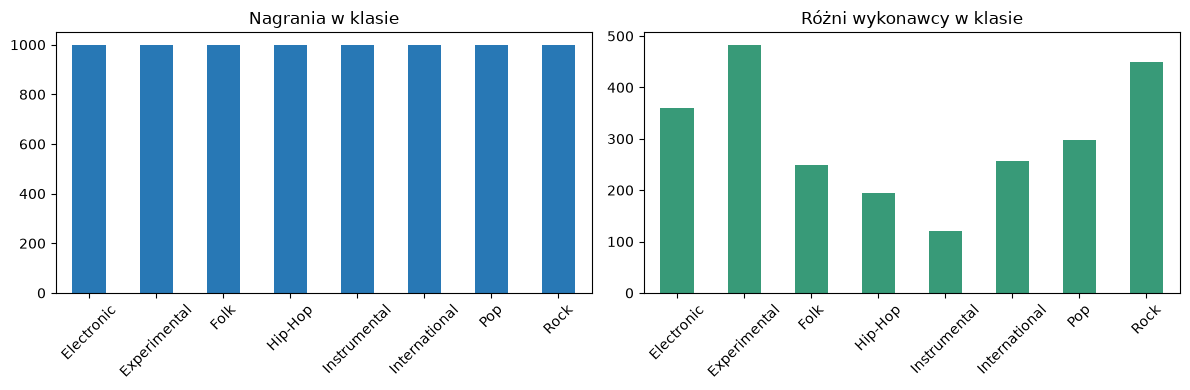

In [2]:
classes = pd.read_csv(REPORTS / 'classes.csv', index_col=0)
display(classes)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
classes['tracks'].plot.bar(ax=axes[0], title='Nagrania w klasie', color='#2878b5')
classes['artists'].plot.bar(ax=axes[1], title='Różni wykonawcy w klasie', color='#389a78')
for ax in axes:
    ax.set_xlabel(''); ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

### Braki danych i wykluczenia

Raport braków obejmuje wszystkie pola metadanych podzbioru small. Opisy artystów
i pozostałe pola nie są cechami modelu. Do kwalifikacji wymagamy artist_id, genre_top
i wpisu licencji. Sama obecność nazwy licencji nie zastępuje przeglądu jej warunków.
Metadane FMA: CC BY 4.0; audio: indywidualne licencje twórców. Nie publikujemy audio.


In [3]:
display(tracks.isna().sum().to_frame('braki w polach używanych w projekcie'))
missing = pd.read_csv(REPORTS / 'metadata_missing.csv', index_col=0)
display(missing[missing['missing'] > 0])
display(pd.read_csv(REPORTS / 'licenses.csv'))
display(pd.read_csv(REPORTS / 'excluded.csv'))

,braki w polach używanych w projekcie
artist_id,0
artist_name,0
album_id,0
title,0
genre,0
license,5
original_duration_s,0
official_split,0
audio_path,0


,missing
album.date_released,2663
album.engineer,6858
album.information,1498
album.producer,6596
album.type,231
artist.active_year_begin,6458
artist.active_year_end,7642
artist.associated_labels,7151
artist.bio,2086
artist.latitude,5101


,license,tracks
0,Art Libre,6
1,Attribution,547
2,Attribution 2.0 France,1
3,Attribution 2.0 UK: England,1
4,Attribution 2.5 Canada,1
...,...,...
58,Noncommercial Sampling Plus,8
59,Public Domain,40
60,Public Domain Mark 1.0,18
61,Sampling Plus,3


,track_id,artist_id,artist_name,album_id,title,genre,license,original_duration_s,official_split,audio_path,exclusion_reason
0,3270,417,Arborea,1705,Song for Obol,Folk,NaN,288,training,003/003270.mp3,missing_license;
1,3271,417,Arborea,1705,Beirut,Folk,NaN,166,training,003/003271.mp3,missing_license;
2,3272,417,Arborea,1705,Seadrift,Folk,NaN,174,training,003/003272.mp3,missing_license;
3,3273,417,Arborea,1705,Redbird,Folk,NaN,173,training,003/003273.mp3,missing_license;
4,3274,417,Arborea,1705,Forewarned,Folk,NaN,349,training,003/003274.mp3,missing_license;
5,51785,10397,Rolemusic,9741,Yellow Dust,Electronic,Attribution-NonCommercial-ShareAlike 3.0 Inter...,113,training,051/051785.mp3,exact_audio_duplicate;
6,57371,2240,Justice Yeldham,10572,March Of The Bodypumpers,Instrumental,Attribution-NonCommercial-NoDerivatives (aka M...,294,training,057/057371.mp3,exact_audio_conflicting_labels;
7,72149,2240,Justice Yeldham,12799,March Of The Bodypumpers,Experimental,Attribution-Noncommercial-Share Alike 3.0 Unit...,294,training,072/072149.mp3,exact_audio_conflicting_labels;
8,86761,15106,Marco Trovatello,14588,Be Sweet,Rock,Attribution-Noncommercial 3.0 Germany,207,training,086/086761.mp3,exact_audio_duplicate;
9,98565,15196,Hi-Rez,15948,Brandon Clark,Hip-Hop,Attribution-NonCommercial,158,training,098/098565.mp3,decode_error_or_empty;


### Dokładne i potencjalne duplikaty

Sprawdzamy powtórzone identyfikatory i identyczne wiersze metadanych. Zgodność
znormalizowanych tytułu i artysty wyznacza tylko kandydatów do przeglądu (np. wersje live).
Pełny audyt audio liczy SHA-256 pliku MP3 i odkodowanego PCM wraz z sample rate i liczbą
kanałów. Identyczne PCM z różnymi etykietami wykluczamy; wśród pozostałych zachowujemy
najniższy kwalifikujący się track_id. Powiązanych artystów nadal łączymy w jedną grupę.
Brak dokładnej zgodności nie wyklucza remasterów, innych kodowań lub przesuniętych kopii.
Audytu podobieństwa sygnału nie deklarujemy jako wykonanego.


In [4]:
assert tracks.index.is_unique
print('Identyczne wiersze metadanych:', summary['metadata_duplicate_rows'])
print('Wiersze z powtórzonym tytułem i artystą:', summary['metadata_title_duplicate_candidates'])
display(pd.read_csv(REPORTS / 'duplicate_title_candidates.csv').head(12))
for name in ['duplicates_file_sha256.csv', 'duplicates_pcm_sha256.csv']:
    path = REPORTS / name
    if path.exists() and summary['audio_audited']:
        result = pd.read_csv(path)
        print(name, ':', len(result), 'wierszy')
        display(result.head(10))

Identyczne wiersze metadanych: 0
Wiersze z powtórzonym tytułem i artystą: 145


,track_id,artist_id,artist_name,album_id,title,genre,license,original_duration_s,official_split,audio_path,title_normalized,artist_normalized
0,1682,1259,The Sounds of Taraab,429,Nie Zama Nie Sema,International,Attribution-Noncommercial-Share Alike 3.0 Unit...,354,training,001/001682.mp3,nie zama nie sema,the sounds of taraab
1,1683,1259,The Sounds of Taraab,429,Mapenzi Matamu,International,Attribution-Noncommercial-Share Alike 3.0 Unit...,312,training,001/001683.mp3,mapenzi matamu,the sounds of taraab
2,3904,559,Michael Chapman,1105,Sometimes,Folk,Attribution-NonCommercial-ShareAlike 3.0 Inter...,263,training,003/003904.mp3,sometimes,michael chapman
3,3906,559,Michael Chapman,988,Sometimes,Folk,Attribution-NonCommercial-ShareAlike 3.0 Inter...,264,training,003/003906.mp3,sometimes,michael chapman
4,3910,559,Michael Chapman,1105,Kodak Ghosts,Folk,Attribution-NonCommercial-ShareAlike 3.0 Inter...,361,training,003/003910.mp3,kodak ghosts,michael chapman
5,3912,559,Michael Chapman,1105,Fahey's Flag,Folk,Attribution-NonCommercial-ShareAlike 3.0 Inter...,218,training,003/003912.mp3,fahey's flag,michael chapman
6,4234,1259,The Sounds of Taraab,760,Mapenzi Matamu,International,Attribution-NonCommercial-ShareAlike 3.0 Inter...,317,training,004/004234.mp3,mapenzi matamu,the sounds of taraab
7,6330,1259,The Sounds of Taraab,1981,Nie Zama Nie Sema,International,Attribution-Noncommercial-Share Alike 3.0 Unit...,201,training,006/006330.mp3,nie zama nie sema,the sounds of taraab
8,11333,1048,Gen Ken Montgomery,2778,Instrumental,Experimental,Attribution-Noncommercial-Share Alike 3.0 Unit...,159,training,011/011333.mp3,instrumental,gen ken montgomery
9,11334,1048,Gen Ken Montgomery,2778,Instrumental,Experimental,Attribution-Noncommercial-Share Alike 3.0 Unit...,90,training,011/011334.mp3,instrumental,gen ken montgomery


duplicates_file_sha256.csv : 0 wierszy


,track_id,exists,decode_ok,bytes,file_sha256,pcm_sha256,duration_s,sample_rate,channels,error


duplicates_pcm_sha256.csv : 24 wierszy


,track_id,exists,decode_ok,bytes,file_sha256,pcm_sha256,duration_s,sample_rate,channels,error
0,45102,True,True,721036,a15711dd833dd7c1cc9df68fd0353a86d2b6b7e953b3e6...,2e6dfbc1734122bab99a99e833038a6d1e64950ced114b...,29.976576,44100.0,1.0,NaN
1,51785,True,True,721044,45678f7d312a4a430eb02aa006191d9589b8ba7146e66b...,2e6dfbc1734122bab99a99e833038a6d1e64950ced114b...,29.976576,44100.0,1.0,NaN
2,57371,True,True,721116,b3475d16bd3f27712f03f2ec07ebe58c7260c65663184e...,a219fde95f756587a38c687286592d506b30779976c179...,29.976576,44100.0,2.0,NaN
3,72149,True,True,721057,aa577ee1e57598c90790b8a3d7ca6feb1bc966334c3ae2...,a219fde95f756587a38c687286592d506b30779976c179...,29.976576,44100.0,2.0,NaN
4,74348,True,True,1202332,f93a7152d20d5491e8225124717e92b0b36dc6200a015e...,9462b2c0a25d5a172de4004f0fcb76c4ce66b2c822b81e...,30.002698,44100.0,2.0,NaN
5,86761,True,True,1202360,aaef3e44d4fa4b8ee133e6ab40ace0c52f9da40d4d37d9...,9462b2c0a25d5a172de4004f0fcb76c4ce66b2c822b81e...,30.002698,44100.0,2.0,NaN
6,114212,True,True,721617,21d06d7fcbd84f5ed35d330ca7c6818678045574e5fba6...,a4818094bdde67d8976877a8ae9cc3f748c5380fb58f6e...,30.002698,44100.0,2.0,NaN
7,114222,True,True,721600,2fbe8a75dc70d52b08ecf11380b2dbbd63019a2b2f0b2c...,840d6b043b61c5fad2a406e076b30dfde77a72838528e9...,30.002698,44100.0,2.0,NaN
8,114223,True,True,720976,c13fe7040e6a44e3bc73bf27d1f65f1c5e8af385e1380b...,f18e9c4091fd7275d99b25c00ba1058c55d00e51cf27b2...,29.976576,44100.0,2.0,NaN
9,114235,True,True,1201637,13cd7650e7bf4fab6da4029589aa08ee64d1001e5d4b6a...,d0d9cbb592b7f24d8e36393f289f4f11aac78cc3f0473e...,29.988979,48000.0,2.0,NaN


### Statystyki rzeczywistych wejść i przykłady

`original_duration_s` opisuje oryginalny utwór, **nie czas fragmentu MP3**. Długości
wejścia mierzymy z liczby faktycznie odkodowanych próbek. Próg kwalifikacji to 10 s,
ustalony przed modelowaniem: minimum jednego 10-sekundowego okna dla encodera.
Krótsze i niedekodowalne pliki wykluczamy z obu przyszłych reprezentacji.
[Errata FMA](https://github.com/mdeff/fma/wiki) opisuje m.in. puste i skrócone nagrania.


,duration_s,bytes,sample_rate,channels
count,7994.000000,8.000000e+03,7994.000000,7994.000000
mean,29.988159,9.968770e+05,44261.896422,1.989367
std,0.012650,2.300291e+05,1267.865876,0.102573
min,29.964580,1.298000e+03,22050.000000,1.000000
25%,29.976576,7.974140e+05,44100.000000,2.000000
50%,29.976576,9.961625e+05,44100.000000,2.000000
75%,30.002698,1.201314e+06,44100.000000,2.000000
max,30.002698,1.205694e+06,48000.000000,2.000000


Niedekodowalne lub puste: 6
Odkodowane, krótsze niż 10 s: 0


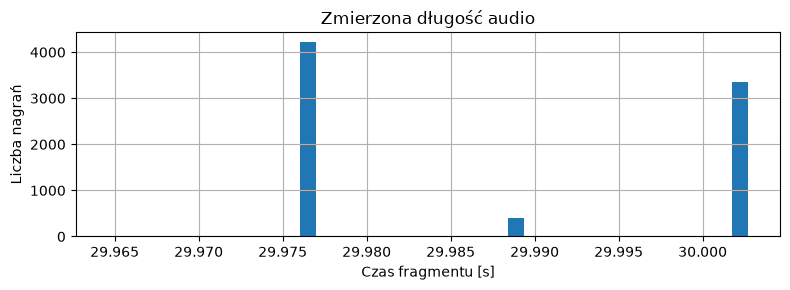

,track_id,artist_id,artist_name,album_id,title,genre,license,original_duration_s,official_split,audio_path
0,2,1,AWOL,1,Food,Hip-Hop,Attribution-NonCommercial-ShareAlike 3.0 Inter...,168,training,000/000002.mp3
1,5,1,AWOL,1,This World,Hip-Hop,Attribution-NonCommercial-ShareAlike 3.0 Inter...,206,training,000/000005.mp3
2,10,6,Kurt Vile,6,Freeway,Pop,Attribution-NonCommercial-NoDerivatives (aka M...,161,training,000/000010.mp3
3,140,54,Alec K. Redfearn & the Eyesores,61,Queen Of The Wires,Folk,Attribution-Noncommercial-No Derivative Works ...,253,training,000/000140.mp3
4,141,54,Alec K. Redfearn & the Eyesores,60,Ohio,Folk,Attribution-Noncommercial-No Derivative Works ...,182,training,000/000141.mp3
5,148,57,Contradiction,66,Blackout 2,Experimental,Attribution-Noncommercial-Share Alike 3.0 Unit...,138,validation,000/000148.mp3
6,182,64,Ariel Pink's Haunted Graffiti,80,Jules Lost His Jewels,Rock,Attribution-Noncommercial-No Derivative Works ...,228,test,000/000182.mp3
7,213,66,Au,86,Boute,Pop,Attribution-NonCommercial-ShareAlike 3.0 Inter...,247,training,000/000213.mp3
8,255,80,Bird Names,100,We Want to be Old,Rock,Attribution-Noncommercial-Share Alike 3.0 Unit...,182,training,000/000255.mp3
9,424,91,Brian Joseph Davis,124,The Ambient Honky,Experimental,Attribution-NonCommercial-ShareAlike 3.0 Inter...,76,training,000/000424.mp3


In [5]:
audio = None
audio_path = REPORTS / 'audio_audit.csv'
if summary['audio_audited']:
    audio = pd.read_csv(audio_path, index_col='track_id')
    display(audio[['duration_s', 'bytes', 'sample_rate', 'channels']].describe())
    print('Niedekodowalne lub puste:', summary['audio_decode_errors_or_empty'])
    print('Odkodowane, krótsze niż 10 s:', summary['audio_shorter_than_10s'])
    fig, ax = plt.subplots(figsize=(8, 3))
    audio['duration_s'].dropna().hist(bins=40, ax=ax)
    ax.set(xlabel='Czas fragmentu [s]', ylabel='Liczba nagrań', title='Zmierzona długość audio')
    fig.tight_layout()
    plt.show()
else:
    print('Pełnego audytu audio jeszcze nie wykonano. Nie zastępujemy go metadanymi.')
display(pd.read_csv(REPORTS / 'examples.csv'))

## 3. Liczba nagrań i niezależnych jednostek

Tabela podaje nagrania, unikalnych wykonawców oraz szersze grupy powiązanych
nagrań. W klasie Instrumental validation i final test obejmują po 18 wykonawców.
Wynik dla tej klasy może silnie zależeć od kilku artystów. Przy wyznaczaniu
przedziałów ufności można losować całe grupy, uwzględniając zależność utworów.


In [6]:
manifest = pd.read_csv(ROOT / 'splits/draft/manifest.csv', index_col='track_id')
split_order = ['train', 'validation', 'final_test']
counts = manifest.groupby('split').agg(
    nagrania=('artist_id', 'size'), wykonawcy=('artist_id', 'nunique'),
    grupy=('group_id', 'nunique'),
)
display(counts.reindex(split_order))
display(pd.crosstab(manifest['genre'], manifest['split']).reindex(columns=split_order))
display(manifest.groupby(['genre', 'split'])['artist_id'].nunique().unstack().reindex(columns=split_order))

,nagrania,wykonawcy,grupy
split,,,
train,5595,1614,1222
validation,1189,344,266
final_test,1192,348,268


split,train,validation,final_test
genre,,,
Electronic,700,150,147
Experimental,700,149,149
Folk,698,149,148
Hip-Hop,700,146,150
Instrumental,696,149,149
International,700,150,150
Pop,701,147,150
Rock,700,149,149


split,train,validation,final_test
genre,,,
Electronic,252,54,54
Experimental,338,72,72
Folk,174,37,37
Hip-Hop,136,29,29
Instrumental,83,18,18
International,179,38,39
Pop,207,45,45
Rock,313,68,67


## 4. Możliwe źródła wycieku danych

| Ryzyko | Zabezpieczenie |
| --- | --- |
| Wspólny wykonawca, alias, album lub dokładna kopia audio | Powiązane nagrania trafiają do jednej grupy, również przy powiązaniach przechodnich. Zgodność nazw jest heurystyką i może łączyć homonimy. |
| Okna lub augmentacje tego samego nagrania | Dziedziczą podział oryginału. Model zwraca jedną predykcję na nagranie. |
| Skalowanie, imputacja i selekcja cech | Dopasowanie parametrów tylko na train. |
| Wybór reprezentacji i hiperparametrów | Porównania na validation. Final test służy do końcowej oceny wybranego systemu. |
| Metadane zdradzające klasę lub wykonawcę | Model korzysta z cech audio. Etykiety służą do uczenia i oceny, a identyfikatory do grupowania. |

Pozostają ryzyka podobnych nagrań bez identycznego sygnału oraz możliwego
pokrycia z danymi użytymi do pretreningu PANNs na AudioSet.


## 5. Utworzenie i uzasadnienie podziału

Docelowe proporcje **70/15/15%** zostawiają większość danych do uczenia i dwa
porównywalne zbiory do wyboru modelu oraz końcowej oceny. Algorytm z `scripts/audit.py`
przypisuje całe grupy i równoważy liczbę nagrań oraz wykonawców dla każdej klasy.
Oficjalny podział rozdziela wykonawców, ale część szerszych grup przecina jego
granice. Dlatego tworzymy własny podział i odtwarzamy go poniżej z wyników audytu.


In [7]:
groups = leakage_groups(tracks, audio)
eligible = tracks.loc[manifest.index]
recreated = make_splits(eligible, groups.loc[eligible.index])
pd.testing.assert_series_equal(groups.loc[manifest.index], manifest['group_id'], check_names=False)
pd.testing.assert_series_equal(recreated, manifest['split'], check_names=False)
assert manifest.index.is_unique
assert manifest.groupby('artist_id')['split'].nunique().max() == 1
assert manifest.groupby('group_id')['split'].nunique().max() == 1
print('Odtworzono zapisany podział. Wykonawcy i grupy są rozłączne.')
print('Szersze grupy przecinające oficjalny podział:', summary['official_leakage_groups_in_multiple_splits'])

Odtworzono zapisany podział. Wykonawcy i grupy są rozłączne.
Szersze grupy przecinające oficjalny podział: 66


## 6. Metryka główna i metryki pomocnicze

**Macro-F1** to średnia F1 dla ośmiu gatunków. Każda klasa ma równą wagę,
więc dobry wynik na jednej nie przesłania słabego wyniku na innych.
Accuracy pokazuje odsetek poprawnych predykcji. Precision, recall, F1 i liczebność
dla każdej klasy oraz macierz pomyłek pomagają ustalić, które gatunki model myli.
Osobno zmierzymy czas ekstrakcji cech, treningu i predykcji oraz podamy użyty sprzęt.

## 7. Seed i zasady losowości

Używamy **seed = 42**. W podziale NumPy rozstrzyga nim remisy kolejności grup.
W kolejnych eksperymentach zapiszemy seed klasyfikatora oraz, jeśli dotyczy, ustawienia
Python/NumPy/PyTorch, wersje bibliotek i urządzenie. Wszystkie porównania użyją tych
samych podziałów. Seed ustalamy przed uzyskaniem wyników modeli.

## 8. Źródło danych, klasy, licencja i ograniczenia

Używamy [FMA Small i metadanych FMA](https://github.com/mdeff/fma) (Defferrard i in.,
ISMIR 2017). Klasa pochodzi z pola `track.genre_top` autorów zbioru. Osiem klas to
Electronic, Experimental, Folk, Hip-Hop, Instrumental, International, Pop i Rock.

Metadane są na CC BY 4.0, a nagrania mają indywidualne warunki licencyjne.
Zestawienie jest w `results/audit/licenses.csv`. Pięć nagrań bez wpisu licencji
wyłączono. Przegląd warunków dla pozostałych nagrań pozostaje do domknięcia.

Pojedyncza etykieta upraszcza wielogatunkowość muzyki. Balans liczby utworów
nie odzwierciedla rozkładu gatunków ani wykonawców w populacji. Dekoder zgłaszał
ostrzeżenia dla części MP3, a hashe wykrywają jedynie dokładną zgodność.
[Errata FMA](https://github.com/mdeff/fma/wiki)

## 9. Zapis i kontrola identyfikatorów

Skrypt audytu zapisuje `splits/train_ids.csv`, `splits/validation_ids.csv` oraz
`splits/test_ids.csv`. Kolumna `id` to identyfikator utworu FMA, `artist_id` oznacza
wykonawcę, a `group_id` szerszą grupę powiązań. Poniżej sprawdzamy kompletność,
rozłączność oraz zgodność eksportów z manifestem.


In [8]:
files = {'train': 'train_ids.csv', 'validation': 'validation_ids.csv', 'final_test': 'test_ids.csv'}
ids = {}
for split, filename in files.items():
    exported = pd.read_csv(ROOT / 'splits' / filename).set_index('id')
    assert exported.index.is_unique
    ids[split] = set(exported.index)
    for column in ('group_id', 'artist_id'):
        pd.testing.assert_series_equal(exported[column], manifest.loc[exported.index, column], check_names=False)
    assert ids[split] == set(manifest.index[manifest['split'].eq(split)])
    assert set(manifest.loc[manifest['split'].eq(split), 'genre']) == set(CLASSES)
    print(f'splits/{filename} — {len(exported)} identyfikatorów')
assert not ids['train'] & ids['validation']
assert not ids['train'] & ids['final_test']
assert not ids['validation'] & ids['final_test']
assert set.union(*ids.values()) == set(manifest.index)
print('Kontrola rozłączności i kompletności: OK')
print('Status final test:', 'zamrożony' if summary['final_test_frozen'] else 'podział roboczy')

splits/train_ids.csv — 5595 identyfikatorów
splits/validation_ids.csv — 1189 identyfikatorów
splits/test_ids.csv — 1192 identyfikatorów
Kontrola rozłączności i kompletności: OK
Status final test: podział roboczy


### Odtworzenie audytu i oddanie

Audyt: `python scripts/audit.py --audio-dir E:/zum-fma/fma_small`.
Dokładny interpreter lokalny: `.venv/Scripts/python.exe`.
Pełne dane można też pobrać w środowisku Colab/Kaggle skryptem
`python scripts/download_data.py small --dest /content/fma_data` po umieszczeniu tam projektu.
Nie potrzeba GPU do Zadania 1.

Po zatwierdzeniu protokołu i warunków licencji zapisujemy ostateczne identyfikatory,
zamrażamy podział i publikujemy commit z tagiem `task-1`.

### Opcjonalny odsłuch przykładów z train


In [9]:
# Odsłuch wyłącznie przykładów z roboczego train — opcjonalny.
# Włącz lokalnie; wyczyść wyniki tej komórki przed commitem (audio nie trafia do repo).
PLAY_AUDIO = False
from IPython.display import Audio
audio_dir = Path(os.environ.get('FMA_AUDIO_DIR', 'E:/zum-fma/fma_small'))
examples = manifest[manifest['split'].eq('train')].sort_index().groupby('genre').head(1)
for track_id, row in examples.iterrows():
    path = audio_dir / row['audio_path']
    if PLAY_AUDIO and path.exists():
        display(Markdown(f"**{row['genre']}** — track_id={track_id}, {row['artist_name']}: {row['title']}"))
        display(Audio(filename=str(path), embed=True))
    else:
        print(f"{row['genre']}: track_id={track_id}; plik dostępny={path.exists()}; odsłuch włączony={PLAY_AUDIO}")

Hip-Hop: track_id=2; plik dostępny=True; odsłuch włączony=False
Pop: track_id=10; plik dostępny=True; odsłuch włączony=False
Folk: track_id=140; plik dostępny=True; odsłuch włączony=False
Experimental: track_id=148; plik dostępny=True; odsłuch włączony=False
Rock: track_id=255; plik dostępny=True; odsłuch włączony=False
International: track_id=853; plik dostępny=True; odsłuch włączony=False
Electronic: track_id=1482; plik dostępny=True; odsłuch włączony=False
Instrumental: track_id=10250; plik dostępny=True; odsłuch włączony=False
